# 17. Simultaneous heat and mass transfer

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 7 and 16

A wet surface in air does two things at once: it exchanges heat with the air, and it loses
water to it. The two are tied together, because every kilogram of water that evaporates
takes its latent heat from the surface. Left alone, the surface cools until the heat that
the air brings in pays exactly for the evaporation. That balance gives the *wet-bulb
temperature*, the oldest instrument of humidity measurement, the temperature of a sweating
skin and of a cooling tower's water, and the lowest temperature an evaporative cooler can
reach. Chapter 16 met it in passing, as the temperature of a falling drop. This chapter
builds the balance properly. Its tools are the properties of moist air (psychrometrics),
the analogy of Chapter 16 in Lewis's form, and the coupled equations of heat and vapour
along a wetted pad.

The engineering question comes from the data centres being built in Kazakhstan. Servers
reject their heat to air, and in a dry continental climate the cheapest way to cool that air
is to blow it through a wetted pad. How far can a pad cool the air on a summer day in Astana
and in Shymkent, how many hours of the day does it suffice, what limits it, and how much water does
it use? The checks compare the psychrometric formulas with a real-gas humid-air model, and
the simple pad formula with the full nonlinear equations marched through the pad.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import _property_fits, convective_mass, properties, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import _property_fits, convective_mass, properties, reference
from engtransport.plotting import panel_label, use_style

use_style()
cm = convective_mass
P_ATM = 101325.0

## 17.1 Moist air

Atmospheric air is a mixture of dry air and water vapour, both close to ideal gases at
ordinary pressures. Since the dry air passes through most equipment unchanged, quantities
are measured per kilogram of dry air. The *humidity ratio* $W$ is the mass of vapour per
kilogram of dry air, and the *relative humidity* $\varphi$ is the partial pressure of
vapour over its saturation value at the same temperature:

$$
W = 0.622\,\frac{p_v}{P - p_v} ,
\qquad
\varphi = \frac{p_v}{p_{sat}(T)} ,
\tag{17.1}
$$

where 0.622 is the ratio of the molar masses of water and dry air and $P$ the total
pressure. The enthalpy of moist air, per kilogram of dry air and measured from dry air and
liquid water at 0 °C, is

$$
h = c_{pa}t + W\left(h_{fg,0} + c_{pv}t\right) ,
\tag{17.2}
$$

with $t$ in °C, $c_{pa} = 1006$ J/(kg K) for dry air, $c_{pv} = 1860$ J/(kg K) for the
vapour and $h_{fg,0} = 2.501$ MJ/kg the latent heat at 0 °C. The second term is the
enthalpy of the vapour: its latent heat plus its sensible heat. The *humid heat*
$c_s = c_{pa} + Wc_{pv}$ is the heat capacity of the mixture per kilogram of dry air. Air at
35 °C and 20 % relative humidity holds 7.0 g of water per kilogram of dry air; saturated at
35 °C it would hold 36.5 g. That difference is the room the air has for evaporation.

## 17.2 The wet surface and the wet-bulb temperature

Let air at $T$ and $W$ flow past a wet surface that receives no heat except from the air.
Two temperatures describe where the surface settles. The first is a thermodynamic one.
Let the air flow through a long, insulated channel over water until it is saturated, the
water being supplied at the temperature it ends with. The energy balance per kilogram of
dry air defines the *adiabatic saturation temperature* $T_{as}$:

$$
h(T, W) + \left(W_{s} - W\right)c_w t_{as} = h\left(T_{as}, W_{s}\right) ,
\qquad W_s = W_{sat}(T_{as}) ,
\tag{17.3}
$$

where the middle term is the small enthalpy of the liquid added. It depends only on the
state of the air: it is a property, which is why psychrometric charts carry its lines.

The second is the temperature of an actual wet surface in a stream: a thermometer bulb
wrapped in wet cloth, a leaf, the film on a pad. Heat arrives by convection,
$h(T - T_s)$; vapour leaves at $\dot m'' = g^*\ln(1 + B)$ with the Spalding number of
Chapter 16, which in humidity ratios is $B = (W_s - W)/(1 + W)$. In steady state the
heat pays for the evaporation, $h(T - T_s) = \dot m''h_{fg}$, or

$$
c_s\,r\left(T - T_s\right) = h_{fg}(T_s)\,\ln\!\left(1 + \frac{W_s - W}{1 + W}\right) ,
\qquad
r = \frac{h}{g^*c_s} ,
\tag{17.4}
$$

with $W_s = W_{sat}(T_s)$. The ratio $r$ of the heat transfer coefficient to the mass
conductance, in units of the humid heat, is the *psychrometric ratio*. By the analogy of
Chapter 16, for a surface in a boundary layer

$$
r = Le^{2/3} ,
\qquad
Le = \frac{\alpha}{D_{AB}} \approx 0.86 \ \text{for water vapour in air} ,
\tag{17.5}
$$

so $r \approx 0.91$; for a drop at rest ($Nu = Sh = 2$) $r = Le$, Eq. (16.11). Lewis (1922)
noticed that for air and water $r$ is close to 1, and that with $r = 1$ and a small $B$,
Eq. (17.4) is the same balance as (17.3): the wet-bulb temperature equals the adiabatic
saturation temperature. This *Lewis relation* is why a simple thermometer measures a
property of the air. It is an accident of the air–water pair; for organic vapours $Le$ is
nearer 2 and the two temperatures differ by several kelvin. Carrier (1911) built his
psychrometric chart on it.

In [2]:
# Section 17.1-17.2: properties and wet-bulb temperatures
T_f = 300.0
air = properties.dry_air_properties(T_f)
D_v = properties.water_vapour_diffusivity_air(T_f)
Le = air["alpha"] / D_v
r_bl, r_sphere = Le ** (2 / 3), Le
print(f"water vapour in air at 27 C: Sc = {air['nu'] / D_v:.3f}, Pr = {air['Pr']:.3f}, Le = {Le:.3f};"
      f" psychrometric ratio Le^(2/3) = {r_bl:.3f}")
W_sat35 = cm.humidity_ratio(308.15, 1.0)
for T, RH in ((308.15, 0.20), (293.15, 0.60), (311.15, 0.10)):
    W = cm.humidity_ratio(T, RH)
    T_as = cm.adiabatic_saturation_temperature(T, W)
    T1, Tbl, Tsp = (cm.wet_surface_temperature(T, W, r) for r in (1.0, r_bl, r_sphere))
    print(f"{T - 273.15:.0f} C, {100 * RH:.0f} %: W = {1e3 * W:.2f} g/kg, h = {cm.moist_air_enthalpy(T, W) / 1e3:.1f} kJ/kg;"
          f" T_as = {T_as - 273.15:.2f} C; wet surface r = 1: {T1 - 273.15:.2f}, r = Le^(2/3): {Tbl - 273.15:.2f},"
          f" r = Le: {Tsp - 273.15:.2f} C")
print(f"saturated at 35 C: W = {1e3 * W_sat35:.1f} g/kg")

water vapour in air at 27 C: Sc = 0.611, Pr = 0.707, Le = 0.863; psychrometric ratio Le^(2/3) = 0.907
35 C, 20 %: W = 6.97 g/kg, h = 53.1 kJ/kg; T_as = 18.88 C; wet surface r = 1: 18.94, r = Le^(2/3): 18.43, r = Le: 18.18 C
20 C, 60 %: W = 8.71 g/kg, h = 42.2 kJ/kg; T_as = 15.15 C; wet surface r = 1: 15.16, r = Le^(2/3): 14.99, r = Le: 14.90 C
38 C, 10 %: W = 4.09 g/kg, h = 48.7 kJ/kg; T_as = 17.53 C; wet surface r = 1: 17.59, r = Le^(2/3): 16.91, r = Le: 16.57 C
saturated at 35 C: W = 36.5 g/kg


At 35 °C and 20 % humidity the adiabatic saturation temperature is 18.9 °C. A wet surface
with Lewis's $r = 1$ settles 0.06 K above it, the difference coming from the blowing factor
and from the latent heat at the surface temperature. A ventilated wet-bulb thermometer
($r = 0.91$) reads 18.4 °C, and a still drop ($r = Le = 0.86$) 18.2 °C, close to the
18.1 °C Chapter 16 found with properties at the film temperature. The differences are half
a kelvin, small for most engineering; but read as if it were the adiabatic saturation
temperature, a ventilated wet bulb understates the relative humidity by up to 3.5
percentage points in dry air at 20 °C, which is why psychrometric tables are made for a
stated kind of instrument.

## 17.3 Evaporative coolers

In a direct evaporative cooler, air is blown through a pad of corrugated cellulose sheets
kept wet by recirculated water. The water settles at the temperature at which it neither
gains nor loses heat, the wet-surface temperature (17.4) of the air passing it. Along the
pad, with $\xi$ the fraction of its depth, the air loses heat to the film and gains vapour
from it:

$$
\frac{dT}{d\xi} = -NTU\left(T - T_s\right) ,
\qquad
\frac{dW}{d\xi} = \frac{NTU}{r}\ln\!\left(1 + \frac{W_s - W}{1 + W}\right) ,
\tag{17.6}
$$

where $NTU = haL/(\rho u c_s)$ is the number of transfer units of the pad, with $a$ the
wetted area per volume, $L$ the depth and $u$ the face velocity. With Lewis's relation and
a small $B$, the surface stays at the adiabatic saturation temperature of the entering air
(the air moves along a line of constant $T_{as}$), Eq. (17.6) becomes linear, and

$$
\frac{T_{out} - T_{as}}{T_{in} - T_{as}} = \frac{W_s - W_{out}}{W_s - W_{in}} = e^{-NTU} ,
\qquad
\varepsilon = \frac{T_{in} - T_{out}}{T_{in} - T_{as}} = 1 - e^{-NTU} ,
\tag{17.7}
$$

the effectiveness of a heat exchanger with one stream at constant temperature
(Chapter 11). Pads are sold by their *saturation effectiveness* $\varepsilon$: typical
cellulose pads 100–200 mm deep reach 0.75–0.9 at face velocities of 2–3 m/s. Here a pad
with $NTU = 1.9$ ($\varepsilon = 0.85$) is assumed. A deeper pad raises the NTU in
proportion, at the cost of pressure drop; a faster air flow lowers it slowly, since $h$
rises with velocity almost as fast as the flow.

## 17.4 Evaporative precooling of a data centre

Consider a data hall with 1 MW of servers, cooled by outdoor air that is filtered,
precooled by a wetted pad when needed, and supplied to the cold aisle; the air leaves the
servers 12 K warmer (assumed), so the hall needs $\dot m_a = 1\text{ MW}/(c_s\cdot 12\text{ K})
= 82$ kg/s of air, through 28 m² of pad at 2.5 m/s. The supply must stay at or below
24 °C with a dew point of at most 15 °C, that is $W \le 10.6$ g/kg (assumed design limits,
of the kind servers are specified for). Part of the air bypasses the pad so that the
mixture is at 24 °C:

$$
f = \frac{T_{in} - T_{set}}{T_{in} - T_{out}} ,
\qquad
W_{sup} = W_{in} + f\left(W_{out} - W_{in}\right) ,
\qquad
\dot m_w = \dot m_a f\left(W_{out} - W_{in}\right) ,
\tag{17.8}
$$

with $f$ the fraction through the pad and $\dot m_w$ the water evaporated. If that
mixture would be too humid, $f$ is reduced until $W_{sup}$ meets the limit, and a chiller
trims the remaining heat $\dot m_a c_s(T_{sup} - T_{set})$. Two summer
design days are assumed: Astana, with the air between 17 and 31 °C and a humidity ratio of
8.0 g/kg; Shymkent, in the south, between 22 and 38 °C with 7.5 g/kg. In both the
temperature is taken as sinusoidal, coldest at 05:00.

In [3]:
NTU_pad, dT_servers, Q_it = 1.9, 12.0, 1.0e6
T_set, Td_max = 297.15, 288.15
c_s = cm.CP_DRY_AIR + 0.008 * cm.CP_VAPOUR
m_air = Q_it / (c_s * dT_servers)
print(f"air flow {m_air:.1f} kg/s; pad face area at 2.5 m/s: {m_air / (properties.dry_air_properties(300.0)['rho'] * 2.5):.1f} m2;"
      f" pad effectiveness {1 - math.exp(-NTU_pad):.3f}")
hours = np.arange(0.0, 24.0, 0.25)
days = {"Astana": (17.0, 31.0, 0.0080), "Shymkent": (22.0, 38.0, 0.0075)}


def design_day(t_min, t_max, W, td_max=Td_max):
    """Outdoor air, pad and bypass through one design day; a chiller trims what the pad may not do."""
    T = 273.15 + 0.5 * (t_min + t_max) - 0.5 * (t_max - t_min) * np.cos(2 * np.pi * (hours - 5) / 24)
    W_lim = cm.humidity_ratio(td_max, 1.0)
    out = {k: np.zeros(hours.size) for k in ("T_as", "T_pad", "T_sup", "W_sup", "water", "trim", "mode")}
    out["T"] = T
    for i, t in enumerate(T):
        T_out, W_out, _ = cm.evaporative_pad(t, W, NTU_pad)
        out["T_as"][i], out["T_pad"][i] = cm.adiabatic_saturation_temperature(t, W), T_out
        if t <= T_set:                                   # outdoor air alone
            out["T_sup"][i], out["W_sup"][i] = t, W
            continue
        f_T = min(1.0, (t - T_set) / (t - T_out))         # pad fraction for 24 C
        f_W = max(0.0, (W_lim - W) / (W_out - W))         # pad fraction allowed by the dew point
        f = min(f_T, f_W)
        out["T_sup"][i] = t - f * (t - T_out)
        out["W_sup"][i] = W + f * (W_out - W)
        out["water"][i] = m_air * f * (W_out - W)
        out["trim"][i] = m_air * c_s * max(out["T_sup"][i] - T_set, 0.0)
        out["mode"][i] = 1 if out["trim"][i] < 1e-6 else 2
    return out


res = {name: design_day(*v) for name, v in days.items()}
W_limit = cm.humidity_ratio(Td_max, 1.0)
print(f"supply limits: 24 C and dew point 15 C, W = {1e3 * W_limit:.2f} g/kg (RH {100 * cm.relative_humidity(T_set, W_limit):.0f} % at 24 C)")
for name, r in res.items():
    hrs = [0.25 * np.sum(r["mode"] == m) for m in (0, 1, 2)]
    i_pk = np.argmax(r["T"])
    f_full_W = cm.evaporative_pad(r["T"][i_pk], days[name][2], NTU_pad)[1]
    print(f"{name}: outdoor air alone {hrs[0]:.2f} h, pad {hrs[1]:.2f} h, pad and chiller {hrs[2]:.2f} h;"
          f" hottest hour {r['T'][i_pk] - 273.15:.1f} C: full pad gives {r['T_pad'][i_pk] - 273.15:.1f} C"
          f" (T_as {r['T_as'][i_pk] - 273.15:.1f} C) at {1e3 * f_full_W:.2f} g/kg; supply {r['T_sup'][i_pk] - 273.15:.1f} C,"
          f" chiller trim {r['trim'][i_pk] / 1e3:.0f} kW ({0.25 * np.sum(r['trim']) / 1e3:.0f} kWh per day);"
          f" water {3600 * r['water'].max():.0f} kg/h at most, {0.25 * 3600 * r['water'].sum() / 1e3:.2f} t per day")
for td in (291.15, 294.15):
    for name, v in days.items():
        r = design_day(*v, td_max=td)
        print(f"dew point limit {td - 273.15:.0f} C, {name}: pad and chiller {0.25 * np.sum(r['mode'] == 2):.2f} h,"
              f" trim {0.25 * np.sum(r['trim']) / 1e3:.0f} kWh per day, water {0.25 * 3600 * r['water'].sum() / 1e3:.2f} t per day")

air flow 81.6 kg/s; pad face area at 2.5 m/s: 27.8 m2; pad effectiveness 0.850
supply limits: 24 C and dew point 15 C, W = 10.63 g/kg (RH 57 % at 24 C)
Astana: outdoor air alone 12.25 h, pad 8.50 h, pad and chiller 3.25 h; hottest hour 31.0 C: full pad gives 20.3 C (T_as 18.4 C) at 12.45 g/kg; supply 24.7 C, chiller trim 57 kW (127 kWh per day); water 772 kg/h at most, 6.33 t per day
Shymkent: outdoor air alone 5.75 h, pad 7.50 h, pad and chiller 10.75 h; hottest hour 38.0 C: full pad gives 22.9 C (T_as 20.2 C) at 13.78 g/kg; supply 30.5 C, chiller trim 540 kW (3660 kWh per day); water 918 kg/h at most, 13.10 t per day


dew point limit 18 C, Astana: pad and chiller 0.00 h, trim 0 kWh per day, water 6.52 t per day


dew point limit 18 C, Shymkent: pad and chiller 3.75 h, trim 212 kWh per day, water 18.15 t per day
dew point limit 21 C, Astana: pad and chiller 0.00 h, trim 0 kWh per day, water 6.52 t per day
dew point limit 21 C, Shymkent: pad and chiller 0.00 h, trim 0 kWh per day, water 18.46 t per day


In Astana the outdoor air alone is cool enough for 12.25 hours of the design day. With the
pad, the supply is held at 24 °C for another 8.5 hours. For the 3.25 hours around the
afternoon peak the full pad could still reach 20.3 °C, but the air would leave with
12.5 g/kg, above the 10.6 g/kg allowed; the pad must be throttled, the supply rises to
24.7 °C, and a chiller removes at most 57 kW per megawatt of servers, 127 kWh over the day.
In Shymkent the hotter air is drier, and the pad would cool it further, to 22.9 °C at the
38 °C peak; but the pad has more to do, adds more water, and for 10.75 hours the dew point
limits it. The chiller then carries up to 540 kW per megawatt, 3.7 MWh over the day. The
limit is not the temperature an evaporative cooler can reach but the water it puts into the
air. Relaxing the dew-point limit to 18 °C removes the chiller in Astana and leaves 3.75
hours in Shymkent; at 21 °C the pad covers every hour in both. The water is the other bill:
the pads evaporate up to 0.77 t an hour per megawatt in Astana and 0.92 t in Shymkent, 6.3
and 13.1 t over the design day.

In [4]:
# Figure 17.1 data: a psychrometric chart and wet-bulb depressions
T_chart = np.linspace(273.15 + 0.5, 273.15 + 45, 200)
paths = {}
for name, (t_min, t_max, W) in days.items():
    T_pk = 273.15 + t_max
    sol = reference.wetted_pad_march(T_pk, W, NTU_pad, 1.0)
    paths[name] = sol
RH_grid = np.linspace(0.05, 0.95, 19)
depress = {}
for t in (20.0, 30.0, 40.0):
    T = t + 273.15
    W_g = cm.humidity_ratio(T, RH_grid)
    depress[t] = np.array([T - cm.adiabatic_saturation_temperature(T, w) for w in W_g])
psy_err = {}
for t in (20.0, 30.0, 40.0):
    T = t + 273.15
    W_g = cm.humidity_ratio(T, RH_grid)
    T_as = np.array([cm.adiabatic_saturation_temperature(T, w) for w in W_g])
    T_wb = np.array([cm.wet_surface_temperature(T, w, r_bl) for w in W_g])
    # relative humidity inferred from a ventilated wet bulb read as if it were T_as
    inferred = []
    for tw in T_wb:
        target = tw
        lo, hi = 1e-4, 1.0
        for _ in range(60):
            mid = 0.5 * (lo + hi)
            if cm.adiabatic_saturation_temperature(T, cm.humidity_ratio(T, mid)) < target:
                lo = mid
            else:
                hi = mid
        inferred.append(0.5 * (lo + hi))
    psy_err[t] = (np.array(inferred) - RH_grid) * 100
    print(f"{t:.0f} C: depression {depress[t][2]:.1f} K at RH {100 * RH_grid[2]:.0f} %;"
          f" reading a ventilated wet bulb as T_as understates RH by {-psy_err[t].min():.1f} points at most")

20 C: depression 11.5 K at RH 15 %; reading a ventilated wet bulb as T_as understates RH by 3.5 points at most


30 C: depression 15.5 K at RH 15 %; reading a ventilated wet bulb as T_as understates RH by 2.6 points at most


40 C: depression 19.6 K at RH 15 %; reading a ventilated wet bulb as T_as understates RH by 1.8 points at most


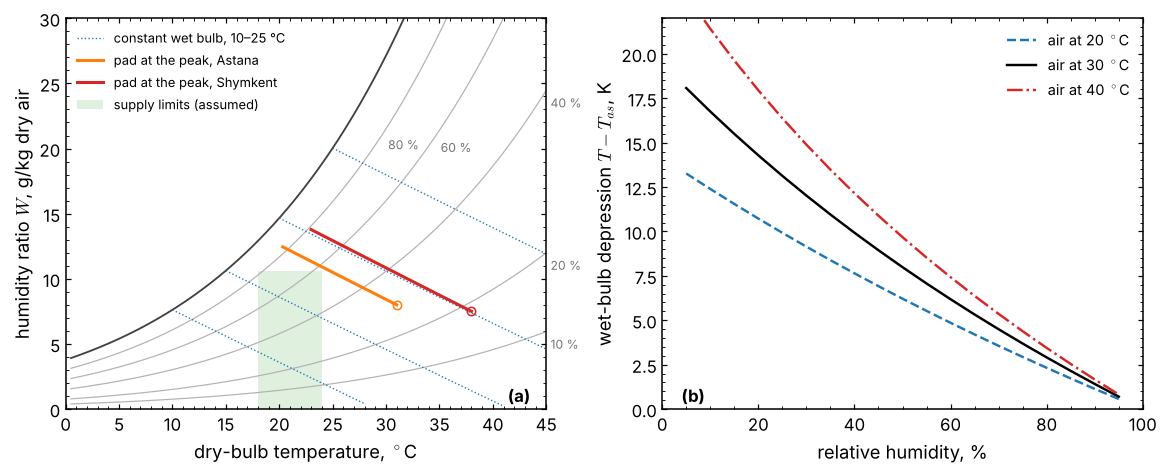

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
for rh in (0.1, 0.2, 0.4, 0.6, 0.8, 1.0):
    ax1.plot(T_chart - 273.15, 1e3 * cm.humidity_ratio(T_chart, rh), "-", color="0.25" if rh == 1.0 else "0.7",
             lw=1.2 if rh == 1.0 else 0.8)
    if rh < 1.0:
        i = np.searchsorted(1e3 * cm.humidity_ratio(T_chart, rh), 21.0) if rh > 0.45 else -1
        ax1.text(T_chart[i] - 273.15 + 0.4, 1e3 * cm.humidity_ratio(T_chart[i], rh) - 0.4, f"{100 * rh:.0f} %",
                 fontsize=8, color="0.45", ha="left", va="top")
for t_wb in (10.0, 15.0, 20.0, 25.0):
    W_w = cm.humidity_ratio(t_wb + 273.15, 1.0)
    T_line = np.linspace(t_wb, 45.0, 30) + 273.15
    W_line = W_w - (cm.CP_DRY_AIR * (T_line - t_wb - 273.15)) / (cm.H_FG0 + cm.CP_VAPOUR * (T_line - 273.15) - cm.CP_LIQUID * t_wb)
    keep = W_line > 0
    ax1.plot(T_line[keep] - 273.15, 1e3 * W_line[keep], ":", color="C0", lw=0.9)
ax1.plot([], [], ":", color="C0", lw=0.9, label="constant wet bulb, 10–25 °C")
for (name, sol), color in zip(paths.items(), ("C1", "C3")):
    ax1.plot(sol["T"] - 273.15, 1e3 * sol["W"], "-", color=color, lw=2.0, label=f"pad at the peak, {name}")
    ax1.plot(sol["T"][0] - 273.15, 1e3 * sol["W"][0], "o", color=color, mfc="none")
ax1.fill_between([18, 24], [0, 0], [1e3 * W_limit] * 2, color="C2", alpha=0.15, lw=0,
                 label="supply limits (assumed)")
ax1.set_xlabel(r"dry-bulb temperature, $^\circ$C")
ax1.set_ylabel(r"humidity ratio $W$, g/kg dry air")
ax1.set_xlim(0, 45)
ax1.set_ylim(0, 30)
ax1.legend(loc="upper left", fontsize=8.5)
panel_label(ax1, "(a)", x=0.92, y=0.06)

for (t, d), style in zip(depress.items(), ("C0--", "k-", "C3-.")):
    ax2.plot(100 * RH_grid, d, style, label=fr"air at {t:.0f} $^\circ$C")
ax2.set_xlabel("relative humidity, %")
ax2.set_ylabel(r"wet-bulb depression $T - T_{as}$, K")
ax2.set_xlim(0, 100)
ax2.set_ylim(0, 22)
ax2.legend(loc="upper right")
panel_label(ax2, "(b)", x=0.04, y=0.06)
plt.show()

**Figure 17.1.** (a) Psychrometric chart at 1 atm: lines of constant relative humidity
(grey), of constant adiabatic saturation temperature (dotted), the paths of air through the
pad at the hottest hour of the two design days (marched with Eq. 17.6), and the supply
limits. (b) Depression of the adiabatic saturation temperature below the dry-bulb
temperature, against relative humidity.

The pad moves the air along a line of nearly constant wet-bulb temperature, up and to the
left on the chart, and stops short of saturation by the factor $e^{-NTU}$. The depression
in panel (b) is what an evaporative cooler has to work with: 14 K in air at 30 °C and 20 %
humidity, but only 4.5 K at 70 %.

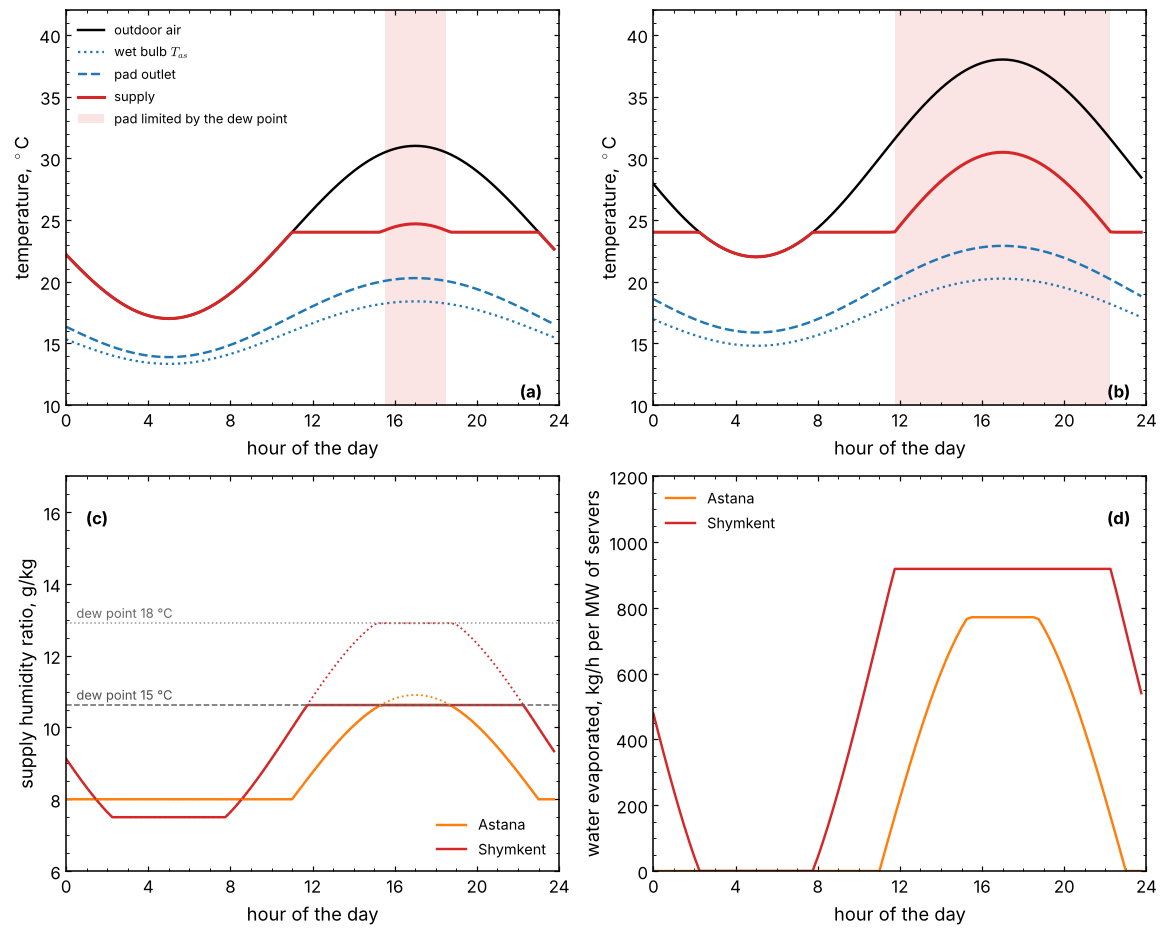

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes
for ax, name in ((ax1, "Astana"), (ax2, "Shymkent")):
    r = res[name]
    ax.plot(hours, r["T"] - 273.15, "k-", label="outdoor air")
    ax.plot(hours, r["T_as"] - 273.15, "C0:", lw=1.5, label="wet bulb $T_{as}$")
    ax.plot(hours, r["T_pad"] - 273.15, "C0--", label="pad outlet")
    ax.plot(hours, r["T_sup"] - 273.15, "C3-", lw=2.0, label="supply")
    bad = r["mode"] == 2
    ax.fill_between(hours, 0, 45, where=bad, color="C3", alpha=0.12, lw=0, label="pad limited by the dew point")
    ax.set_xlabel("hour of the day")
    ax.set_ylabel(r"temperature, $^\circ$C")
    ax.set_xlim(0, 24)
    ax.set_xticks(range(0, 25, 4))
    ax.set_ylim(10, 42)
ax1.legend(loc="upper left", fontsize=8.5)
panel_label(ax1, "(a)", x=0.92, y=0.06)
panel_label(ax2, "(b)", x=0.92, y=0.06)

for (name, r), color in zip(res.items(), ("C1", "C3")):
    ax3.plot(hours, 1e3 * r["W_sup"], "-", color=color, label=name)
ax3.axhline(1e3 * W_limit, color="0.4", ls="--", lw=1.0)
ax3.text(0.5, 1e3 * W_limit + 0.15, "dew point 15 °C", fontsize=8.5, color="0.3")
for (name, (t_min, t_max, W)), color in zip(days.items(), ("C1", "C3")):
    r18 = design_day(t_min, t_max, W, td_max=291.15)
    ax3.plot(hours, 1e3 * r18["W_sup"], ":", color=color, lw=1.2)
ax3.axhline(1e3 * cm.humidity_ratio(291.15, 1.0), color="0.6", ls=":", lw=1.0)
ax3.text(0.5, 1e3 * cm.humidity_ratio(291.15, 1.0) + 0.15, "dew point 18 °C", fontsize=8.5, color="0.4")
ax3.set_xlabel("hour of the day")
ax3.set_ylabel(r"supply humidity ratio, g/kg")
ax3.set_xlim(0, 24)
ax3.set_xticks(range(0, 25, 4))
ax3.set_ylim(6, 17)
ax3.legend(loc="lower right")
panel_label(ax3, "(c)", x=0.04, y=0.92)

for (name, r), color in zip(res.items(), ("C1", "C3")):
    ax4.plot(hours, 3600 * r["water"], "-", color=color, label=name)
ax4.set_xlabel("hour of the day")
ax4.set_ylabel("water evaporated, kg/h per MW of servers")
ax4.set_xlim(0, 24)
ax4.set_xticks(range(0, 25, 4))
ax4.set_ylim(0, 1200)
ax4.legend(loc="upper left")
panel_label(ax4, "(d)", x=0.92, y=0.92)
plt.show()

**Figure 17.2.** Evaporative precooling of a 1 MW data hall on assumed summer design days.
(a) Astana and (b) Shymkent: outdoor, wet-bulb, pad-outlet and supply temperatures; in the
shaded hours the dew-point limit stops the pad short of 24 °C and a chiller trims the rest.
(c) Supply humidity ratio with a dew-point limit of 15 °C (solid) and 18 °C (dotted).
(d) Water evaporated per megawatt of servers (15 °C limit).

## 17.5 Checks

*Psychrometric formulas.* Equations (17.1)–(17.3) treat moist air as an ideal mixture with
constant heat capacities, and use the Magnus formula for the vapour pressure. They are
compared with CoolProp's real-gas humid-air model, which follows the ASHRAE formulation of
Herrmann, Kretzschmar and Gatley (2009), tabulated by `scripts/fit_properties.py` at
20 states from 5 to 45 °C and 10 to 90 % humidity.

*The pad.* The linear formula (17.7) assumes Lewis's relation, a small $B$, a surface held
at the inlet's adiabatic saturation temperature and constant humid heat. The full
equations (17.6), with the local wet-surface temperature (17.4) and the nonlinear
saturation curve, are marched through the pad by `reference.wetted_pad_march`, both with
$r = 1$ and with the boundary-layer value $r = Le^{2/3}$.

In [7]:
ref = np.array(_property_fits.HUMID_AIR_REF)
liquid = ref[:, 4] > 0.5            # the formulas use liquid water; below 0 C the bulb is ice
dW, dh, dT = [], [], []
for t, rh, W_ref, h_ref, twb_ref in ref[liquid]:
    T = t + 273.15
    W = cm.humidity_ratio(T, rh)
    dW.append(W / W_ref - 1)
    dh.append((cm.moist_air_enthalpy(T, W) - h_ref) / 1e3)
    dT.append(cm.adiabatic_saturation_temperature(T, W) - 273.15 - twb_ref)
dW, dh, dT = np.array(dW), np.array(dh), np.array(dT)
print(f"{liquid.sum()} states with the wet bulb above 0 C: W {100 * dW.min():+.2f} to {100 * dW.max():+.2f} %;"
      f" h {dh.min():+.2f} to {dh.max():+.2f} kJ/kg; T_as {dT.min():+.3f} to {dT.max():+.3f} K")
k_pv = 0.0
for t, rh, W_ref, *_ in ref[liquid]:
    T = t + 273.15
    k_pv = max(k_pv, abs(cm.humidity_ratio(T, rh) * 1.0045 / W_ref - 1))
print(f"with the enhancement factor 1.0045 of real moist air, W agrees within {100 * k_pv:.2f} %")

NTU_grid = np.array([0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0])
T_in, W_in = 308.15, cm.humidity_ratio(308.15, 0.20)
T_as_in = cm.adiabatic_saturation_temperature(T_in, W_in)
eff = {}
for r in (1.0, r_bl):
    eff[r] = np.array([(T_in - reference.wetted_pad_march(T_in, W_in, n, r, n_eval=2)["T"][-1]) / (T_in - T_as_in)
                       for n in NTU_grid])
eff_lin = 1 - np.exp(-NTU_grid)
for r, e in eff.items():
    print(f"r = {r:.3f}: effectiveness / (1 - e^-NTU) - 1 from {100 * (e / eff_lin - 1).min():+.2f} to {100 * (e / eff_lin - 1).max():+.2f} %")
prof = {r: reference.wetted_pad_march(T_in, W_in, NTU_pad, r) for r in (1.0, r_bl)}
for r, p in prof.items():
    print(f"r = {r:.3f}, NTU 1.9: outlet {p['T'][-1] - 273.15:.2f} C (Eq. 17.7: {cm.evaporative_pad(T_in, W_in, NTU_pad)[0] - 273.15:.2f} C);"
          f" film {p['T_s'][0] - 273.15:.2f} -> {p['T_s'][-1] - 273.15:.2f} C; T_as of the air {T_as_in - 273.15:.2f} ->"
          f" {cm.adiabatic_saturation_temperature(p['T'][-1], p['W'][-1]) - 273.15:.2f} C")

18 states with the wet bulb above 0 C: W -0.70 to -0.52 %; h -0.76 to -0.01 kJ/kg; T_as +0.001 to +0.042 K
with the enhancement factor 1.0045 of real moist air, W agrees within 0.25 %


r = 1.000: effectiveness / (1 - e^-NTU) - 1 from -0.61 to -0.31 %
r = 0.907: effectiveness / (1 - e^-NTU) - 1 from -0.07 to +2.28 %


r = 1.000, NTU 1.9: outlet 21.37 C (Eq. 17.7: 21.29 C); film 18.94 -> 18.93 C; T_as of the air 18.88 -> 18.92 C
r = 0.907, NTU 1.9: outlet 21.23 C (Eq. 17.7: 21.29 C); film 18.43 -> 18.85 C; T_as of the air 18.88 -> 18.92 C


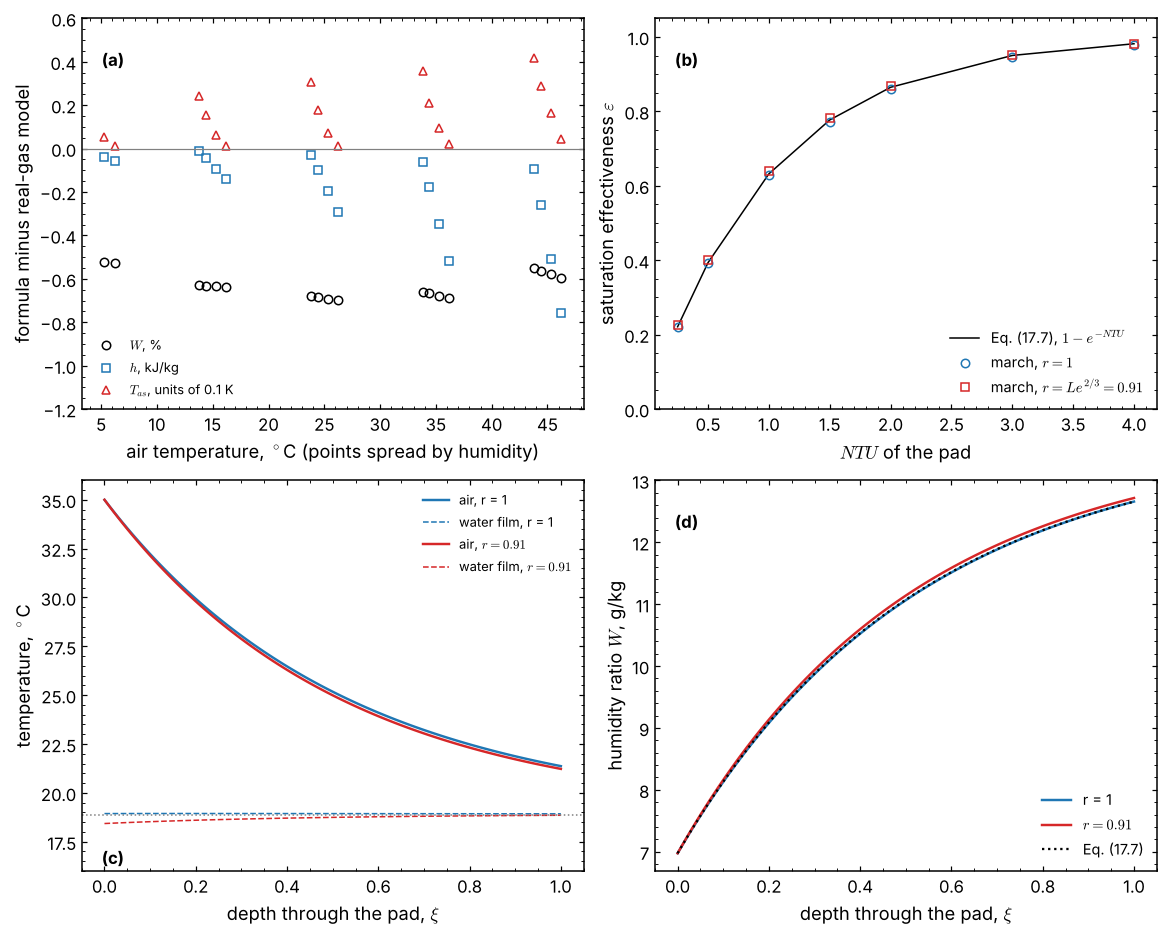

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes
tt = ref[liquid, 0] + 3 * (ref[liquid, 1] - 0.5)
ax1.plot(tt, 100 * dW, "ko", mfc="none", label=r"$W$, %")
ax1.plot(tt, dh, "C0s", ms=5, mfc="none", label=r"$h$, kJ/kg")
ax1.plot(tt, 10 * dT, "C3^", ms=5, mfc="none", label=r"$T_{as}$, units of 0.1 K")
ax1.axhline(0, color="0.5", lw=0.8)
ax1.set_xlabel(r"air temperature, $^\circ$C (points spread by humidity)")
ax1.set_ylabel("formula minus real-gas model")
ax1.set_ylim(-1.2, 0.6)
ax1.legend(loc="lower left", fontsize=8.5)
panel_label(ax1, "(a)", x=0.04, y=0.92)

ax2.plot(NTU_grid, eff_lin, "k-", lw=1.0, label=r"Eq. (17.7), $1 - e^{-NTU}$")
ax2.plot(NTU_grid, eff[1.0], "C0o", mfc="none", label=r"march, $r = 1$")
ax2.plot(NTU_grid, eff[r_bl], "C3s", ms=5, mfc="none", label=fr"march, $r = Le^{{2/3}} = {r_bl:.2f}$")
ax2.set_xlabel(r"$NTU$ of the pad")
ax2.set_ylabel(r"saturation effectiveness $\varepsilon$")
ax2.set_ylim(0, 1.05)
ax2.legend(loc="lower right")
panel_label(ax2, "(b)", x=0.04, y=0.92)

for (r, p), style in zip(prof.items(), ("C0", "C3")):
    lab = "r = 1" if r == 1.0 else fr"$r = {r:.2f}$"
    ax3.plot(p["xi"], p["T"] - 273.15, "-", color=style, label=f"air, {lab}")
    ax3.plot(p["xi"], p["T_s"] - 273.15, "--", color=style, lw=1.0, label=f"water film, {lab}")
ax3.axhline(T_as_in - 273.15, color="0.5", ls=":", lw=1.0)
ax3.set_xlabel(r"depth through the pad, $\xi$")
ax3.set_ylabel(r"temperature, $^\circ$C")
ax3.set_ylim(16, 36)
ax3.legend(loc="upper right", fontsize=8.5)
panel_label(ax3, "(c)", x=0.04, y=0.06)

for (r, p), style in zip(prof.items(), ("C0", "C3")):
    lab = "r = 1" if r == 1.0 else fr"$r = {r:.2f}$"
    ax4.plot(p["xi"], 1e3 * p["W"], "-", color=style, label=lab)
W_lin = cm.humidity_ratio(T_as_in, 1.0) - (cm.humidity_ratio(T_as_in, 1.0) - W_in) * np.exp(-NTU_pad * prof[1.0]["xi"])
ax4.plot(prof[1.0]["xi"], 1e3 * W_lin, "k:", lw=1.5, label="Eq. (17.7)")
ax4.set_xlabel(r"depth through the pad, $\xi$")
ax4.set_ylabel(r"humidity ratio $W$, g/kg")
ax4.legend(loc="lower right")
panel_label(ax4, "(d)", x=0.04, y=0.92)
plt.show()

**Figure 17.3.** Checks. (a) Humidity ratio, enthalpy and adiabatic saturation temperature
from Eqs. (17.1)–(17.3) minus CoolProp's real-gas humid-air model, at 1 atm. (b) Saturation
effectiveness of the pad from the full equations (17.6) against Eq. (17.7), for air at
35 °C and 20 %. (c) Air and water-film temperatures through a pad with $NTU = 1.9$; the
dotted line is the adiabatic saturation temperature of the entering air. (d) Humidity
ratio through the same pad.

The ideal-gas formulas give the humidity ratio 0.5 to 0.7 % low and the enthalpy up to
0.8 kJ/kg low. Most of the first is the *enhancement factor*, the slight increase of the
vapour pressure of water in air over that of pure water, which the Magnus formula leaves
out; with a factor of 1.0045 the humidity ratios agree within 0.25 %. The adiabatic
saturation temperature, the quantity the chapter relies on, agrees within 0.04 K. The pad
formula (17.7) overstates the marched effectiveness by 0.3 to 0.6 % for $r = 1$; the film
temperature changes by 0.01 K through the pad, so treating the water as one temperature is
justified. With the boundary-layer value $r = 0.91$ the film starts 0.5 K colder and warms
through the pad, and the air leaves 0.14 K cooler: the effectiveness rises by up to 2 %.
Both differences are far below the uncertainty in a pad's NTU.

## 17.6 What to trust

* *Psychrometrics* from Eqs. (17.1)–(17.3) are good to about 1 % in humidity and 0.04 K in
  wet-bulb temperature at ordinary conditions; below 0 °C the surface is ice, and at high
  temperatures or pressures the real-gas model should be used.
* *The wet-bulb temperature* of an instrument differs from the adiabatic saturation
  temperature by a few tenths of a kelvin through $r \ne 1$, and by more through radiation
  to the wick (Exercise 3); ventilated psychrometers are built to keep both small.
* *Pads* are rated by experiment; the NTU assumed here stands for a typical cellulose pad,
  and fouling by scale reduces it over a season. The water film is not uniform, and dry
  patches lower the effectiveness.
* *The design days* are idealised sinusoids with an assumed constant humidity; real
  weather data (hourly records for a typical year) are needed for an annual water and energy
  budget, and the supply limits depend on the equipment.

## Summary

* Moist air is described per kilogram of dry air by its humidity ratio and enthalpy,
  Eqs. (17.1)–(17.2); the adiabatic saturation temperature (17.3) is a property of the air.
* A wet surface settles where convected heat pays for evaporation, Eq. (17.4); because the
  psychrometric ratio (17.5) of air and water vapour is close to 1 (Lewis's relation), it
  settles close to the adiabatic saturation temperature: within 0.5 K for a ventilated
  thermometer.
* Air through a wetted pad approaches its wet-bulb temperature as $e^{-NTU}$, Eqs.
  (17.6)–(17.7).
* Evaporative precooling of a data centre on the assumed summer design days is limited by
  the water it adds to the air, not by the temperature it reaches: with a 15 °C dew-point
  limit, a chiller is needed for 3.25 hours of the day in Astana and 10.75 in Shymkent;
  at 21 °C, for none. The pads evaporate 6 to 13 t of water a day per megawatt.

## Exercises

Sample solutions are in [`solutions/part4_mass_transfer/17_solutions.ipynb`](../../solutions/part4_mass_transfer/17_solutions.ipynb).

1. **Reading a psychrometer.** A ventilated psychrometer reads 30.0 °C on the dry bulb and
   20.0 °C on the wet bulb. Find the humidity ratio and relative humidity, first treating
   the wet-bulb reading as the adiabatic saturation temperature, then with the wick's
   psychrometric ratio $Le^{2/3}$. How large is the error in relative humidity, and in which
   direction?
2. **A cooling coil that dehumidifies.** Air at 26 °C and 60 % humidity passes over the
   fins of a cooling coil whose surface is at 10 °C, with a heat transfer coefficient of
   50 W/(m² K) (assumed). Water condenses on the fins. Find the sensible and latent heat
   fluxes, the condensation rate and the *sensible heat ratio* (sensible over total heat).
   What surface temperature would just stop the condensation?
3. **A canvas water bag.** A canvas water bag hangs in the shade in desert air at 40 °C and
   10 % humidity; the canvas is kept wet by seepage. Taking a convective coefficient of
   15 W/(m² K) (assumed), an emissivity of 0.95 for the wet canvas, surroundings at the air
   temperature, and $r = Le^{2/3}$, find the temperature of the canvas. How much warmer is
   it than a wet bulb without radiation, and what is the result in a wind that doubles $h$?
4. **The water budget of a data centre.** A 2 MW data hall in Shymkent uses the pads of
   Section 17.4 on 90 days of a summer like the design day, with the 15 °C dew-point limit.
   The recirculated water must be partly drained (bled) to keep dissolved minerals from
   building up: with three cycles of concentration (an assumed value), the bleed is half
   of the evaporation. Find the water consumed per day and per summer, and the water used
   per kilowatt-hour of server energy. Compare with the energy a chiller would have needed
   to remove the same heat, with a coefficient of performance of 4 (assumed), and with the
   electricity the chiller still needs on the pad's behalf.

## Suggested references

* W. H. Carrier, "Rational psychrometric formulae", *Trans. ASME* **33**, 1005 (1911).
* W. K. Lewis, "The evaporation of a liquid into a gas", *Trans. ASME* **44**, 325 (1922).
* S. Herrmann, H.-J. Kretzschmar and D. P. Gatley, "Thermodynamic properties of real moist
  air, dry air, steam, water, and ice (RP-1485)", *HVAC&R Res.* **15**, 961 (2009).
* I. H. Bell, J. Wronski, S. Quoilin and V. Lemort, "Pure and pseudo-pure fluid
  thermophysical property evaluation and the open-source thermophysical property library
  CoolProp", *Ind. Eng. Chem. Res.* **53**, 2498 (2014).

---

**Previous:** [16. Convective mass transfer](16_convective_mass_transfer.ipynb) &nbsp;·&nbsp; **Next:** [18. A project: from exchanger data to a cleaning schedule](18_cleaning_schedule.ipynb)